In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd

df = pd.read_csv("Placement_Data_Full_Class.csv")

print("Dataset uploaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset uploaded successfully!
Dataset shape: (215, 15)


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nPlacement counts:")
print(df["status"].value_counts())

Column names:
['sl_no', 'gender', 'ssc_p', 'ssc_b', 'hsc_p', 'hsc_b', 'hsc_s', 'degree_p', 'degree_t', 'workex', 'etest_p', 'specialisation', 'mba_p', 'status', 'salary']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 no

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,148.000000
mean,108.000000,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
std,62.209324,10.827205,10.897509,7.358743,13.275956,5.833385,93457.452420
min,1.000000,40.890000,37.000000,50.000000,50.000000,51.210000,200000.000000
25%,54.500000,60.600000,60.900000,61.000000,60.000000,57.945000,240000.000000
50%,108.000000,67.000000,65.000000,66.000000,71.000000,62.000000,265000.000000
75%,161.500000,75.700000,73.000000,72.000000,83.500000,66.255000,300000.000000
max,215.000000,89.400000,97.700000,91.000000,98.000000,77.890000,940000.000000



Missing values:
sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

Placement counts:
status
Placed        148
Not Placed     67
Name: count, dtype: int64


In [4]:
# Create a copy of the dataset
data = df.copy()

# Remove duplicate records
data = data.drop_duplicates()

# Remove serial number, gender, school boards and salary
columns_to_remove = [
    "sl_no",
    "gender",
    "ssc_b",
    "hsc_b",
    "salary"
]

data = data.drop(
    columns=columns_to_remove,
    errors="ignore"
)

# Remove rows without a placement outcome
data = data.dropna(subset=["status"])

# Standardize target labels
data["status"] = data["status"].astype(str).str.strip()

print("Data cleaning completed!")
print("Cleaned shape:", data.shape)

display(data.head())

Data cleaning completed!
Cleaned shape: (215, 10)


,ssc_p,hsc_p,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status
0,67.00,91.00,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed
1,79.33,78.33,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed
2,65.00,68.00,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed
3,56.00,52.00,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed
4,85.80,73.60,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


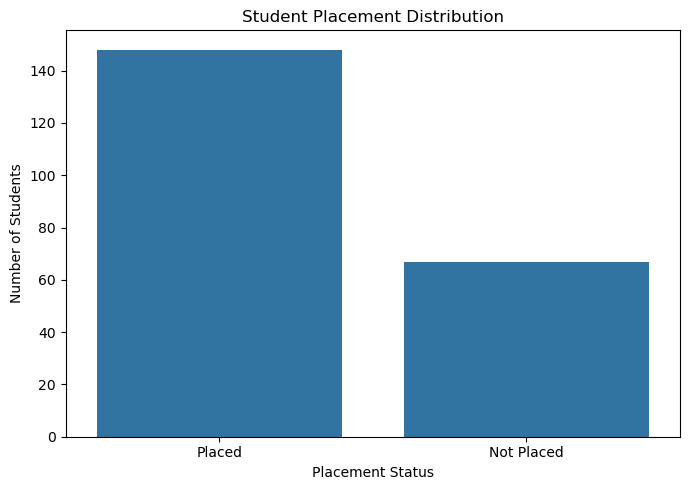

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="status")

plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [8]:
placement_percentage = (
    data["status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(placement_percentage)

status
Placed        68.84
Not Placed    31.16
Name: proportion, dtype: float64


In [9]:
score_columns = [
    "ssc_p",
    "hsc_p",
    "degree_p",
    "etest_p",
    "mba_p"
]

score_columns = [
    col for col in score_columns if col in data.columns
]

average_scores = data.groupby("status")[score_columns].mean()

display(average_scores)

,ssc_p,hsc_p,degree_p,etest_p,mba_p
status,,,,,
Not Placed,57.544030,58.395522,61.134179,69.587910,61.612836
Placed,71.721486,69.926554,68.740541,73.238041,62.579392


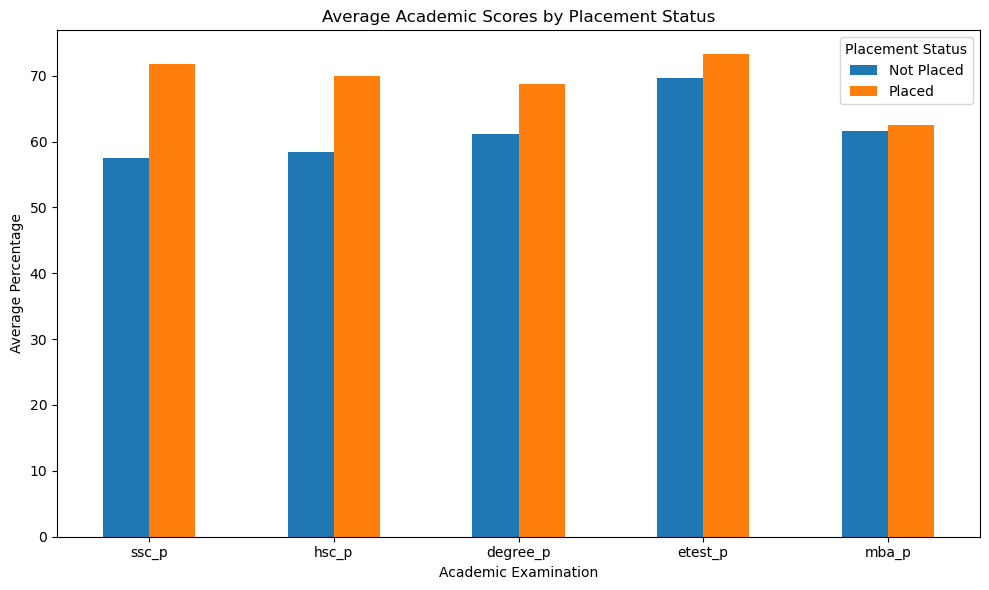

In [10]:
average_scores.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Academic Scores by Placement Status")
plt.xlabel("Academic Examination")
plt.ylabel("Average Percentage")
plt.xticks(rotation=0)
plt.legend(title="Placement Status")
plt.tight_layout()
plt.show()

In [11]:
# Features: information used to make predictions
X = data.drop(columns=["status"])

# Target: what we want to predict
y = data["status"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['ssc_p', 'hsc_p', 'hsc_s', 'degree_p', 'degree_t', 'workex', 'etest_p', 'specialisation', 'mba_p']

Target classes:
['Placed' 'Not Placed']

Feature shape: (215, 9)
Target shape: (215,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 172
Testing records: 43


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Process numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build the complete model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Machine learning pipeline created successfully!")

Machine learning pipeline created successfully!


In [14]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [15]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Placement": y_test,
    "Predicted Placement": y_pred
})

display(results.head(10))

,Actual Placement,Predicted Placement
63,Not Placed,Placed
60,Placed,Placed
132,Placed,Placed
75,Not Placed,Not Placed
16,Placed,Placed
190,Not Placed,Placed
76,Placed,Placed
35,Placed,Placed
51,Not Placed,Not Placed
66,Placed,Placed


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label="Placed",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label="Placed",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label="Placed",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Accuracy:  0.837
Precision: 0.897
Recall:    0.867
F1-score:  0.881

Detailed Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.71      0.77      0.74        13
      Placed       0.90      0.87      0.88        30

    accuracy                           0.84        43
   macro avg       0.81      0.82      0.81        43
weighted avg       0.84      0.84      0.84        43



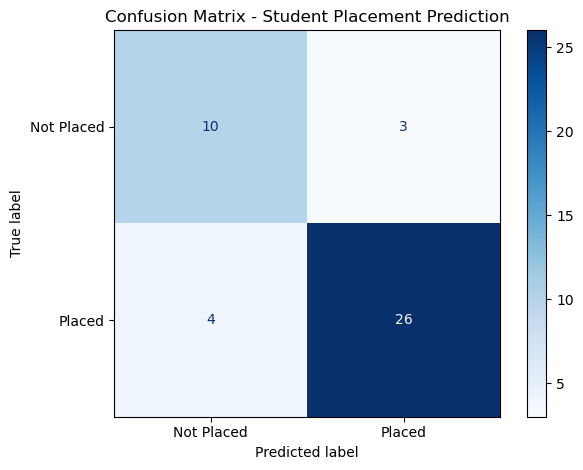

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Not Placed", "Placed"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Student Placement Prediction")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )
}

comparison = []

for name, classifier in models.items():
    # Reuse the preprocessing pipeline
    candidate = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score (Placed)": f1_score(
            y_test, predictions,
            pos_label="Placed",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values("F1 Score (Placed)", ascending=False))

,Model,Accuracy,F1 Score (Placed)
2,Random Forest,0.883721,0.920635
0,Logistic Regression,0.837209,0.881356
1,Decision Tree,0.744186,0.819672


In [19]:
new_student = pd.DataFrame([{
    "ssc_p": 80.0,
    "hsc_p": 75.0,
    "hsc_s": "Science",
    "degree_p": 78.0,
    "degree_t": "Sci&Tech",
    "workex": "No",
    "etest_p": 70.0,
    "specialisation": "Mkt&Fin",
    "mba_p": 75.0
}])

# Keep the same feature order used during training
new_student = new_student.reindex(columns=X.columns)

# Predict placement
prediction = model.predict(new_student)[0]

print("Student Placement Prediction:", prediction)

Student Placement Prediction: Placed


In [20]:
probabilities = model.predict_proba(new_student)[0]

for label, probability in zip(model.classes_, probabilities):
    print(f"{label}: {probability * 100:.2f}%")

Not Placed: 8.12%
Placed: 91.88%


In [21]:
import joblib

joblib.dump(
    model,
    "student_placement_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
